# Assignment 3 — Task 3: Prove the palette
 
Simulate deuteranopia, protanopia, and tritanopia for a palette you choose and for the course palette. Measure the closest pair with OKLab ΔE rather than relying on visual confidence.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from vizlib import PALETTE, save_fig, simulate_cvd, style_defaults, verdict, worst_pair

style_defaults()
MY_PALETTE = ["#1F77B4", "#FF7F0E", "#2CA02C", "#D62728"]
MY_LABEL = "Matplotlib tab10 (first four)"
COURSE_PALETTE = PALETTE["series"] + [PALETTE["series_4th"]]
KINDS = ["normal", "deutan", "protan", "tritan"]

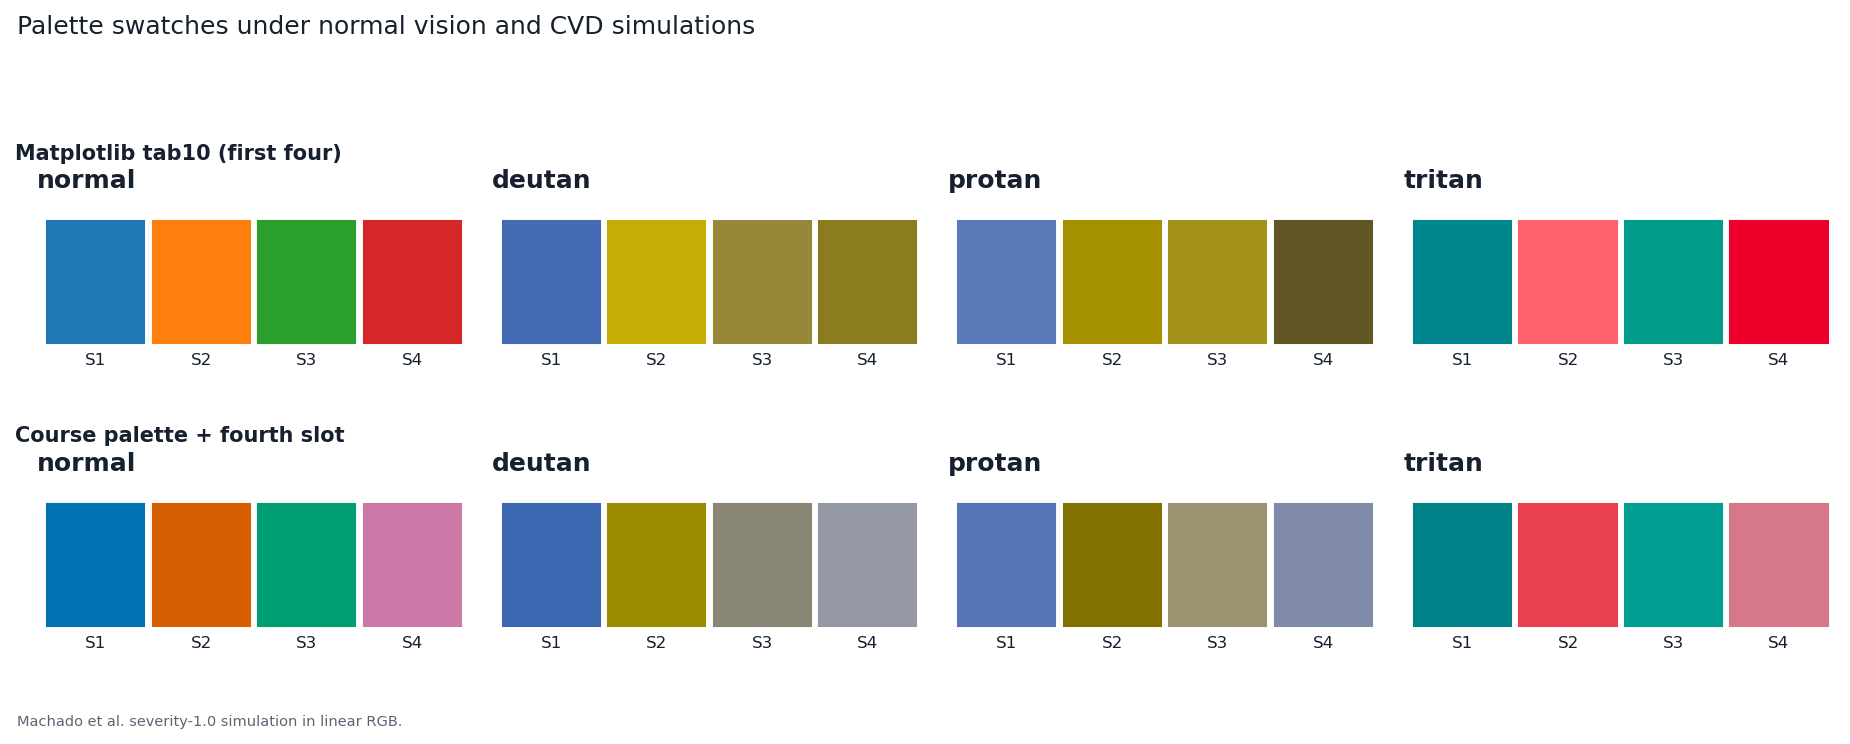

In [2]:
def swatch_sheet(palettes, output):
    fig, axes = plt.subplots(len(palettes), len(KINDS),
                             figsize=(3.1 * len(KINDS), 2.3 * len(palettes)),
                             squeeze=False)
    for row, (palette, label) in enumerate(palettes):
        for col, kind in enumerate(KINDS):
            ax = axes[row, col]
            shown = palette if kind == "normal" else simulate_cvd(palette, kind)
            for i, colour in enumerate(shown):
                ax.add_patch(plt.Rectangle((i, 0), .92, 1, color=colour))
                ax.text(i + .46, -.18, f"S{i+1}", ha="center", fontsize=8)
            ax.set(xlim=(-.1, len(palette)), ylim=(-.35, 1.1), title=kind)
            ax.axis("off")
        axes[row, 0].text(-.05, 1.28, label, transform=axes[row, 0].transAxes,
                          fontsize=10, fontweight="bold")
    fig.suptitle("Palette swatches under normal vision and CVD simulations", x=.01, ha="left")
    fig.tight_layout(rect=[0, 0, 1, .92])
    save_fig(fig, output, "Machado et al. severity-1.0 simulation in linear RGB.")
    plt.show()

swatch_sheet([(MY_PALETTE, MY_LABEL), (COURSE_PALETTE, "Course palette + fourth slot")],
             "task3_palette_swatches.png")

In [3]:
def audit_palette(palette, label):
    print(label)
    for kind in KINDS:
        i, j, first, second, distance = worst_pair(palette, kind)
        print(f"  {kind:7s}: S{i} {first} vs S{j} {second}; dE = {distance:.1f}; {verdict(distance)}")
    print()

audit_palette(MY_PALETTE, MY_LABEL)
audit_palette(COURSE_PALETTE, "Course palette + fourth slot")

Matplotlib tab10 (first four)
  normal : S2 #FF7F0E vs S4 #D62728; dE = 18.6; clear
  deutan : S3 #2CA02C vs S4 #D62728; dE = 4.1; FAILS — same colour
  protan : S2 #FF7F0E vs S3 #2CA02C; dE = 0.7; FAILS — same colour
  tritan : S1 #1F77B4 vs S3 #2CA02C; dE = 6.7; needs a second channel

Course palette + fourth slot
  normal : S2 #D55E00 vs S4 #CC79A7; dE = 16.4; clear
  deutan : S3 #009E73 vs S4 #CC79A7; dE = 7.5; needs a second channel
  protan : S1 #0072B2 vs S4 #CC79A7; dE = 9.5; ok
  tritan : S1 #0072B2 vs S3 #009E73; dE = 8.4; ok



### Rule for more than three categories

Do not solve a category problem by adding unlimited hues. Use direct labels, small multiples, a table, or a second channel such as marker shape and line style. The course palette's fourth slot must carry a redundant encoding or direct labels because its CVD separation and contrast are weaker.

In [4]:
# Optional bonus: simulate a rendered figure if Task 4 has already been run.
from pathlib import Path
from matplotlib.image import imread, imsave
figure_path = Path("partD_figure.png")
if figure_path.exists():
    image = imread(figure_path)
    imsave("task3_partD_deutan.png", simulate_cvd(image, "deutan"))
    print("Saved a deuteranopia simulation of", figure_path)
else:
    print("Run task4.ipynb first to create partD_figure.png.")

Saved a deuteranopia simulation of partD_figure.png


### Submission checklist

- Both palettes are shown before and after simulation.
- All three CVD types are audited.
- The worst pair and ΔE are reported for each palette.
- The rule adds a non-colour channel instead of pretending a larger palette is automatically safe.